<a href="https://colab.research.google.com/github/emersonnjsantos/YOLO_CARPARTS/blob/main/yolo_carparts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

# Load a pretrained segmentation model like YOLO26n-seg
model = YOLO("yolo26n-seg.pt")  # load a pretrained model (recommended for training)

# Train the model on the Carparts Segmentation dataset
results = model.train(data="carparts-seg.yaml", epochs=50, imgsz=640)



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=carparts-seg.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None,

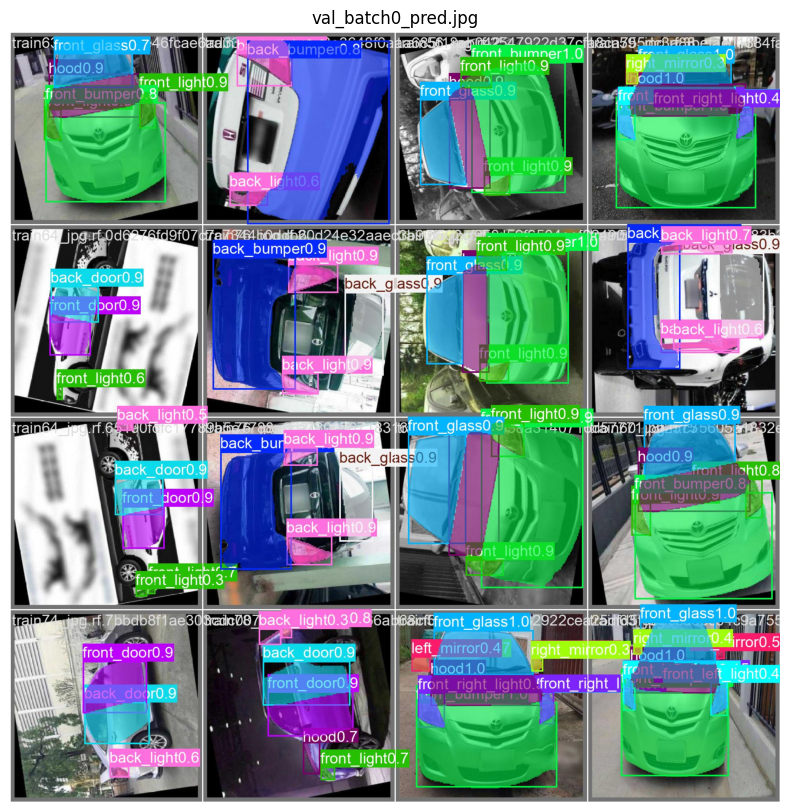

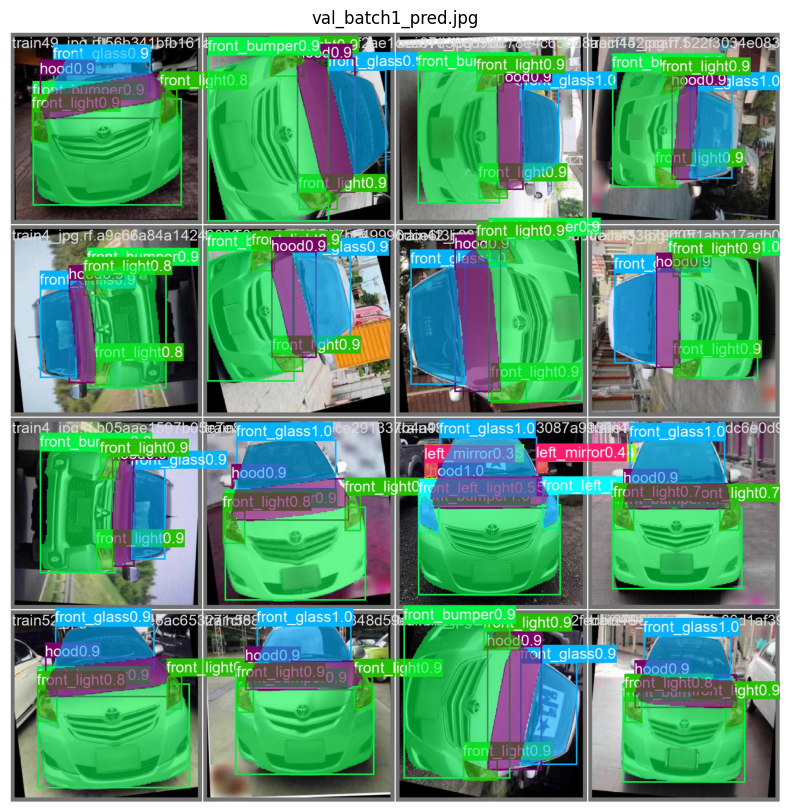

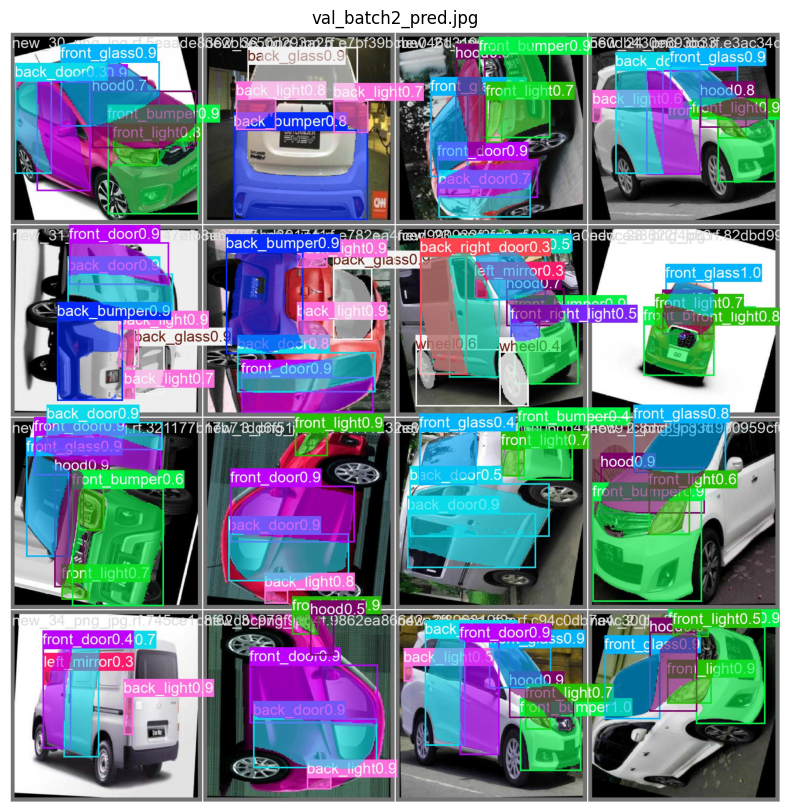

In [ ]:
import glob
import matplotlib.pyplot as plt
import cv2

# Caminho para as imagens de predição geradas na pasta val-2
pred_images = glob.glob('/content/runs/segment/val-2/*_pred.jpg')

if pred_images:
    for img_path in sorted(pred_images):
        # Carrega a imagem
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Plota a imagem
        plt.figure(figsize=(10, 10))
        plt.imshow(img_rgb)
        plt.title(img_path.split('/')[-1])
        plt.axis('off')
        plt.show()
else:
    print('Nenhuma imagem de previsão encontrada em /content/runs/segment/val-2/')


image 1/1 /content/datasets/carparts-seg/images/test/car88_jpg.rf.debc3fd991a81508534a8eefe29abfe9.jpg: 640x640 1 back_bumper, 1 back_glass, 2 back_lights, 15.1ms
Speed: 1.0ms preprocess, 15.1ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/segment/predict


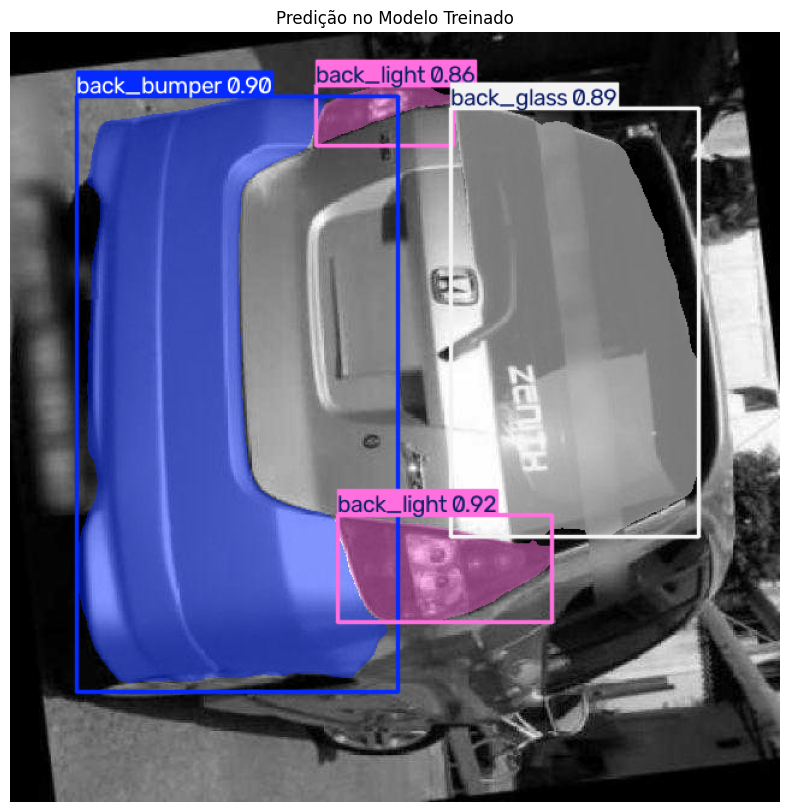

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 1. Carrega o modelo com os melhores pesos obtidos no seu treinamento
model_path = '/content/runs/segment/train/weights/best.pt'
model = YOLO(model_path)

# 2. Define o caminho da nova imagem que você quer testar
# (Substitua pelo caminho do seu próprio arquivo de imagem, ex: 'sua_imagem.jpg')
nova_imagem = '/content/datasets/carparts-seg/images/test/car88_jpg.rf.debc3fd991a81508534a8eefe29abfe9.jpg'

# 3. Executa a predição
results = model.predict(source=nova_imagem, save=True, conf=0.25)

# 4. Exibe o resultado plotado diretamente no notebook
for r in results:
    # O método plot() desenha as caixas, máscaras e rótulos na imagem original
    im_array = r.plot()
    im_rgb = cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 10))
    plt.imshow(im_rgb)
    plt.axis('off')
    plt.title('Predição no Modelo Treinado')
    plt.show()

### 📦 Exportando o Modelo Treinado (ONNX e TFLite)

O Ultralytics YOLO facilita a conversão de pesos `.pt` nativos do PyTorch para formatos otimizados de produção. Vamos exportar os pesos `best.pt` para:
1. **ONNX (`format='onnx'`)** - Excelente para servidores, APIs em Python/C++ ou runtimes multiplataforma.
2. **TFLite (`format='tflite'`)** - Ideal para dispositivos móveis (Android) e IoT.

In [ ]:
from ultralytics import YOLO

# 1. Carrega os melhores pesos gerados durante o treinamento
model_path = '/content/runs/segment/train/weights/best.pt'
model = YOLO(model_path)

# 2. Exporta para o formato ONNX
print("Iniciando a exportação para ONNX...")
onnx_path = model.export(format='onnx', imgsz=640)
print(f"Modelo ONNX exportado com sucesso em: {onnx_path}\n")

# 3. Exporta para o formato TFLite
print("Iniciando a exportação para TFLite...")
tflite_path = model.export(format='tflite', imgsz=640)
print(f"Modelo TFLite exportado com sucesso em: {tflite_path}")

Iniciando a exportação para ONNX...
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n-seg summary (fused): 137 layers, 2,709,129 parameters, 0 gradients, 9.2 GFLOPs

PyTorch: starting from '/content/runs/segment/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 59, 8400), (1, 32, 160, 160)) (6.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 456ms
Prepared 4 packages in 521ms
Installed 4 packages in 29ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: 

/usr/local/lib/python3.13/dist-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.



LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

...

(00:18) [ DONE] LiteRT-Torch Convert > Run LiteRT Converter Passes (+00:00)

(00:18) [ DONE] LiteRT-Torch Convert (+00:18)

(00:00) [START] Write Model to /content/runs/segment/train/weights/best.tflite

(00:00) [ DONE] Write Model to /content/runs/segment/train/weights/best.tflite (+00:00)

LiteRT: export success ✅ 23.9s, saved as '/content/runs/segment/train/weights/best.tflite' (10.7 MB)

Export complete (24.3s)
Results saved to /content/runs/segment/train/weights/best.tflite
Predict:         yolo predict task=segment model=/content/runs/segment/train/weights/best.tflite imgsz=640 
Validate:        yolo val task=segment model=/content/runs/segment/train/weights/best.tflite imgsz=640 data=/usr/local/lib/python3.13/dist-packages/ultralytics/cfg/datasets/carparts-seg.yaml 
Visualize:       https://netron.app
Modelo TFLite exportado com sucesso em: /content/runs/segment/train/weights/best.tflite


### 💾 Salvando os Resultados no Google Drive

O ambiente do Colab é temporário: ao encerrar a sessão, a pasta `/content/runs` é apagada. Esta célula copia todo o treinamento (pesos `best.pt`/`last.pt`, ONNX, TFLite, gráficos e métricas) para o seu Google Drive.

In [ ]:
from google.colab import drive
import shutil, os

drive.mount('/content/drive')

destino = '/content/drive/MyDrive/YOLO_CARPARTS/runs'
os.makedirs(os.path.dirname(destino), exist_ok=True)
shutil.copytree('/content/runs', destino, dirs_exist_ok=True)

print(f'Resultados copiados para: {destino}')
for f in sorted(os.listdir(f'{destino}/segment/train/weights')):
    print(' -', f)

### 🚀 Como Melhorar a Precisão para Classes com Baixo Desempenho

Se algumas classes (como *left_mirror*, *right_mirror* ou peças menores) estão apresentando métricas baixas, você pode aplicar as seguintes técnicas no YOLO:

#### 1. Aumentar e Balancear os Dados (Data Augmentation)
Classes com poucas amostras no dataset tendem a performar mal.
* **Foco em Coleta:** Tente adicionar mais imagens que contenham especificamente as classes com baixo desempenho.
* **Augmentation nativo do YOLO:** O YOLO já possui técnicas automáticas como `mosaic`, `mixup` e `scale`. Você pode forçar ou aumentar esses parâmetros no treinamento.

#### 2. Ajustar Hiperparâmetros de Treinamento
Você pode alterar a forma como o modelo calcula a perda (loss) ou aumentar a resolução:
* **Aumentar o tamanho da imagem (`imgsz`):** Se as peças com baixo desempenho forem muito pequenas (ex: retrovisores), treinar com imagens maiores (ex: `imgsz=1280` se o seu hardware permitir) ajuda o modelo a capturar detalhes finos.
* **Aumentar Épocas (`epochs`):** Às vezes o modelo precisa de mais tempo para convergir em classes difíceis (ex: aumentar de 50 para 100 ou 150 épocas).

#### 3. Congelar Camadas (Transfer Learning Avançado)
Se o modelo estiver esquecendo características gerais, você pode congelar o "backbone" (as primeiras camadas extratoras de características do modelo) para focar o aprendizado apenas na cabeça de segmentação das classes difíceis:
```python
# Exemplo de congelamento das primeiras 10 camadas
model.train(data='carparts-seg.yaml', epochs=50, freeze=10)
```

#### 4. Filtrar por Confiança na Inferência
Na etapa de predição, você pode diminuir ligeiramente o limiar de confiança (`conf`) ou aplicar o **OHEM (Online Hard Example Mining)** focando o treinamento nos exemplos que o modelo costuma errar.